# OCS Model Calibration

This part of the pipeline is intended to independently calibrate the OCS classification model in terms of thresholds and anchors.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.metrics import pairwise_distances
from sklearn.metrics import balanced_accuracy_score, accuracy_score
from matplotlib.colors import PowerNorm

from common.configuration import species_invasive, species_native, species_classes_map, genetic_order_classes


In [2]:
trainval_cls_pred_path = "Save/trainval_classification_predictions.csv"
test_cls_pred_path = "Save/test_classification_predictions.csv"
hist_cls_pred_path = "Save/historical_classification_predictions.csv"

In [3]:
embeddings_colls = [str(i) for i in range(19)]

## Data loading

In [4]:
def sort_data_by_genetic_order(ref_x: np.ndarray, ref_y: pd.Series):
    sorted_pairs = sorted(
        zip(ref_x, ref_y), key=lambda x: genetic_order_classes.index(x[1]))

    # Unzip back to separate lists
    ref_x, ref_y = zip(*sorted_pairs)
    ref_x = np.array(ref_x)
    ref_y = pd.Series(ref_y)
    return ref_x, ref_y

In [5]:
trainval_cls_pred_pd = pd.read_csv(trainval_cls_pred_path, index_col=0)


trainval_cls_pred_pd = trainval_cls_pred_pd.sort_values(by="label", ignore_index=True)
trainval_cls_pred_masked_pd = trainval_cls_pred_pd.copy()
for m_label in species_invasive:
    trainval_cls_pred_masked_pd.loc[trainval_cls_pred_masked_pd.label == m_label, "label"] = "Unknown"

trainval_ref_x = trainval_cls_pred_masked_pd[embeddings_colls].to_numpy()
trainval_ref_y = trainval_cls_pred_masked_pd["label"]

trainval_ref_unmasked_x, trainval_ref_unmasked_y = sort_data_by_genetic_order(trainval_ref_x, trainval_cls_pred_pd["label"])


In [6]:
test_cls_pred_pd = pd.read_csv(test_cls_pred_path, index_col=0)
test_cls_pred_pd = test_cls_pred_pd.sort_values(by="label", ignore_index=True)
test_cls_pred_masked_pd = test_cls_pred_pd.copy()
for m_label in species_invasive:
    test_cls_pred_masked_pd.loc[test_cls_pred_masked_pd.label == m_label, "label"] = "Unknown"

test_ref_x = test_cls_pred_masked_pd[embeddings_colls].to_numpy()
test_ref_y = test_cls_pred_masked_pd["label"]

test_ref_unmasked_x, test_ref_unmasked_y = sort_data_by_genetic_order(test_ref_x, test_cls_pred_pd["label"])


In [7]:
hist_cls_pred_pd = pd.read_csv(hist_cls_pred_path, index_col=0)
# hist_cls_pred_masked_pd = hist_cls_pred_pd.copy()

hist_cls_pred_pd.loc[hist_cls_pred_pd.label == "Populus", "label"] = "Populus tremula"
hist_cls_pred_pd.loc[hist_cls_pred_pd.label == "Gramineae", "label"] = "Poaceae"
hist_cls_pred_pd.loc[hist_cls_pred_pd.label == "0_Not pollen", "label"] = "Not pollen"
hist_cls_pred_pd.loc[hist_cls_pred_pd.label == "0_Unknown-pollen", "label"] = "Unknown"


hist_cls_pred_pd = hist_cls_pred_pd.sort_values(by="label", ignore_index=True)

hist_x = hist_cls_pred_pd[embeddings_colls].to_numpy()
hist_x, hist_y = sort_data_by_genetic_order(hist_x, hist_cls_pred_pd["label"])


## Anchors callibration

To callibrate anchors we estimate centers of mass of distributions in training-validation dataset.

In [8]:
from scipy.stats import skew

def evaluate_anchor(df, label):
    df = df[df.label == label]
    positions: np.ndarray = df[embeddings_colls].to_numpy()
    anchor = np.median(positions, axis=0)
    std = np.std(positions, axis=0)
    return anchor, std

In [9]:
anchor_to_label = {}
anchors_np = np.zeros((19, 19))
for l in species_native:
    a, s = evaluate_anchor(trainval_cls_pred_pd, l)
    anchors_np[species_classes_map[l]] = a
    anchor_to_label[species_classes_map[l]] = l

In [10]:
def classify_(item: np.ndarray, anchors:np.ndarray=anchors_np):
    vec_dist = anchors_np - item
    distances = np.linalg.norm(vec_dist, axis=1)
    closest_class_id = np.argmin(distances)
    closest_label = anchor_to_label[np.argmin(distances)]
    closest_distance = distances[closest_class_id]
    return distances, closest_class_id, closest_label, closest_distance

## OSC Classification procedure

In [11]:
def classify_with_threshold(item: np.ndarray, threshold=4, anchors:np.ndarray=anchors_np):
    vec_dist = anchors_np - item
    distances = np.linalg.norm(vec_dist, axis=1)
    closest_class_id = np.argmin(distances)
    vec_to_closest_anchor = vec_dist[closest_class_id]
    
    distance_to_anchor = np.linalg.norm(vec_to_closest_anchor)
    is_known = distance_to_anchor < threshold

    _label = anchor_to_label[np.argmin(distances)] if is_known else "Unknown"
    _class_id = closest_class_id if is_known else None
    return distances, _class_id, _label, distance_to_anchor


In [12]:
classify_with_threshold(trainval_cls_pred_pd[embeddings_colls].to_numpy()[250])

(array([ 0.67986453, 13.94578515, 13.93371167, 13.82279695, 13.73486492,
        13.56159008, 13.75796362, 14.08291594, 13.8202637 , 13.40096941,
        13.77287285, 13.70910919, 13.70255866, 14.02242968, 13.61507399,
        13.73071232, 13.79520878, 13.62600777, 13.96984734]),
 np.int64(0),
 'Acer',
 np.float64(0.6798645291628665))

## Tune threshold

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

def optimize_threshold_balanced(X, y, thresholds_range, 
                                      unknown_label="Unknown", 
                                      alpha=0.5,
                                      min_samples_per_class=20,
                                      macro_fcn=np.min,
                                      classify_fcn=classify_with_threshold):
    y_arr = np.asarray(y)
    
    # Identify known classes (exclude unknown_label)
    known_classes = sorted([c for c in np.unique(y_arr) if c != unknown_label])
    if len(known_classes) == 0:
        raise ValueError("No known classes found in validation labels.")
    
    true_unknown = (y_arr == unknown_label)
    n_unknown = true_unknown.sum()
    if n_unknown == 0:
        print(" Warning: No unknown samples in validation set. Specificity will be NaN.")
    
    results = []
    best_thresh = None
    best_score = -np.inf
    
    for t in thresholds_range:
        # Uses your exact function - no modifications
        preds = np.array([classify_fcn(item, threshold=t)[2] for item in X])
        
        # --- SPECIFICITY: Unknown rejection rate ---
        if n_unknown > 0:
            correct_rejected = np.sum(true_unknown & (preds == unknown_label))
            specificity = correct_rejected / n_unknown
        else:
            specificity = np.nan  # Cannot compute without unknowns
        
        # --- SENSITIVITY: MACRO-AVERAGED across known classes ---
        class_recalls = []
        class_names = []
        for cls in known_classes:
            mask_true = (y_arr == cls)
            n_cls = mask_true.sum()
            
            if n_cls < min_samples_per_class:
                continue  # Skip underrepresented classes
            
            # Correct predictions for this class: predicted as this class AND not unknown
            correct = np.sum(mask_true & (preds == cls))
            recall = correct / n_cls
            class_recalls.append(recall)
            class_names.append(cls)
        
        if len(class_recalls) == 0:
            macro_sensitivity = 0.0
        else:
            macro_sensitivity = macro_fcn(class_recalls)
        
        # --- COMBINED SCORE ---
        if np.isnan(specificity):
            # Fallback: optimize only macro-sensitivity if no unknowns
            score = macro_sensitivity
        else:
            score = alpha * macro_sensitivity + (1 - alpha) * specificity
        
        results.append({
            "threshold": t,
            "macro_sensitivity": macro_sensitivity,
            "specificity": specificity,
            "score": score,
            "class_recalls": dict(zip(class_names, class_recalls))
        })
            
    macro_sensitivitys = np.array([r["macro_sensitivity"] for r in results])
    specificitys = np.array([r["specificity"] for r in results])
    best_thresh = thresholds_range[(np.argmin(np.abs(macro_sensitivitys - specificitys)))]
    return best_thresh, results

## OCS Performance evaluation

In [14]:
def find_threshold(x, y, macro_fcn=np.min, file_name=None,
                   classify_fcn=classify_with_threshold):
    thresholds_to_test = np.linspace(1.0, 6.0, 40)
    optimal_thresh, metrics = optimize_threshold_balanced(
        X=x,
        y=y,
        thresholds_range=thresholds_to_test,
        unknown_label="Unknown",
        macro_fcn=macro_fcn,
        classify_fcn=classify_fcn
    )
    print(f"Optimal threshold: {optimal_thresh:.3f}")
    print(f"  Macro-sensitivity: {metrics[-1]['macro_sensitivity']:.3f}")
    print(f"  Specificity: {metrics[-1]['specificity']:.3f}")

    # Plot trade-off + per-class recall heatmap
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Main trade-off curve
    sens = [m["macro_sensitivity"] for m in metrics]
    spec = [m["specificity"] for m in metrics]
    threshs = [m["threshold"] for m in metrics]

    ax1.plot(threshs, sens, 'o-', label='Macro-Sensitivity', color='dodgerblue')
    ax1.plot(threshs, spec, 's-',
             label='Specificity (Unknown Rejection)', color='crimson')
    ax1.axvline(optimal_thresh, color='green', linestyle='--',
                label=f'Optimal: {optimal_thresh:.2f}')
    ax1.set_xlabel('Threshold')
    ax1.set_ylabel('Metric Value')
    ax1.set_title('Balanced Sensitivity vs Specificity')
    ax1.grid(True, alpha=0.3)
    ax1.legend()

    # Per-class recall at optimal threshold (heatmap)
    opt_metrics = next(m for m in metrics if abs(
        m["threshold"] - optimal_thresh) < 1e-5)
    class_recalls = opt_metrics["class_recalls"]

    if class_recalls:
        classes = list(class_recalls.keys())
        print(classes)
        classes_gen_sorted = sorted(classes, key=lambda x: genetic_order_classes.index(x))
        classes_gen_sorted.reverse()
        recalls = [class_recalls[c] for c in classes_gen_sorted]
        colors = plt.cm.RdYlGn(recalls)
        bars = ax2.barh(classes_gen_sorted, recalls, color=colors)
        ax2.set_xlabel('Recall')
        ax2.set_title(f'Per-Class Recall at Threshold={optimal_thresh:.2f}')
        ax2.set_xlim(0, 1.05)
        for i, (bar, val) in enumerate(zip(bars, recalls)):
            ax2.text(val + 0.02, i, f'{val:.2f}', va='center', fontsize=9)

    plt.tight_layout()
    if file_name:
        plt.savefig(file_name)
    plt.show()

    return optimal_thresh

Optimal threshold: 1.897
  Macro-sensitivity: 0.978
  Specificity: 0.229
['Acer', 'Alnus', 'Ambrosia', 'Apiaceae', 'Artemisia', 'Betula', 'Chenopodiaceae', 'Corylus', 'Picea', 'Pinus', 'Plantago', 'Poaceae', 'Populus tremula', 'Quercus', 'Rumex', 'Salix', 'Tilia', 'Ulmus', 'Urtica']


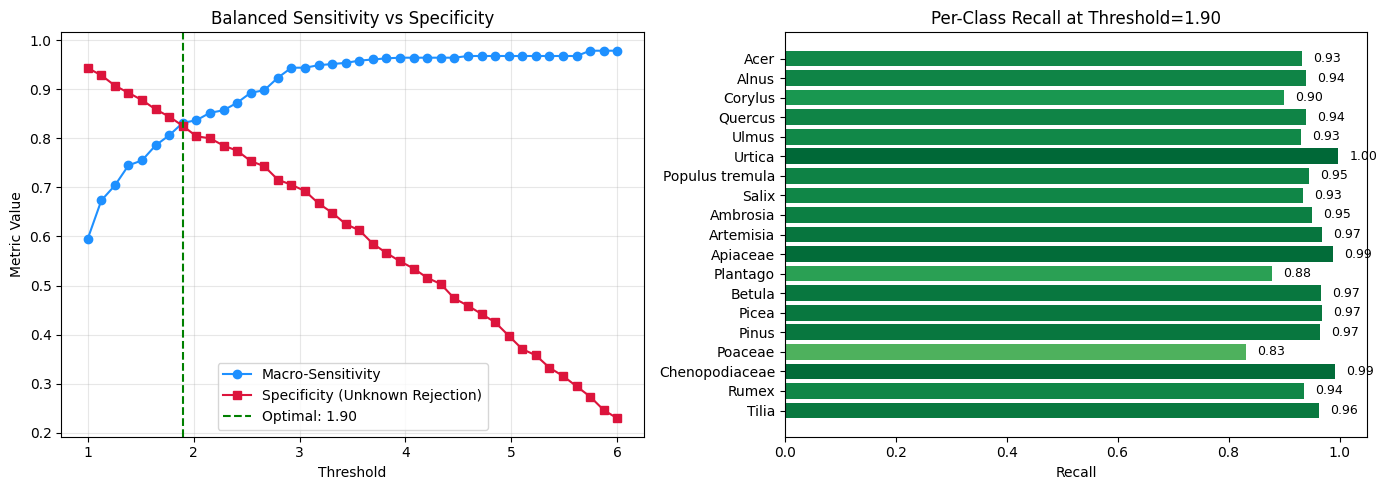

In [15]:
optimal_thresh = find_threshold(np.concatenate([trainval_ref_x]), np.concatenate([trainval_ref_y]), macro_fcn=np.min, file_name=os.path.join("out", "lab_find_threshold.svg"))

### Prediction with oprimal threshold

In [16]:
trainval_ref_pred  = [classify_with_threshold(item, optimal_thresh)[2] for item in trainval_ref_x]
test_ref_pred = [classify_with_threshold(item, optimal_thresh)[2] for item in test_ref_x]

### Confusion matrixes

In [17]:
def plot_confusion_matrix(y_true, y_pred, file_name=None):
    existed_classes = sorted(set(y_true) | set(y_pred))
    classes = []
    for cl in genetic_order_classes:
        if cl in existed_classes:
            classes.append(cl)            

    cm = confusion_matrix(y_true, y_pred, labels=classes)
    plt.figure(figsize=(16, 12))

    # cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    sns.heatmap(cm.T, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes)

    plt.ylabel('Predicted Label', fontsize=12)
    plt.xlabel('True Label', fontsize=12)
    plt.title('Normalized Confusion Matrix', fontsize=14)
    plt.tight_layout()
    if file_name:
        plt.savefig(file_name)
    plt.show()

    # # 1. Create a DataFrame from the 2D array
    df = pd.DataFrame(cm.T)
    # 2. Name the index and columns after their axis numbers
    df.index = classes
    df.columns = classes

    return df

#### Lab reference train and validation subset

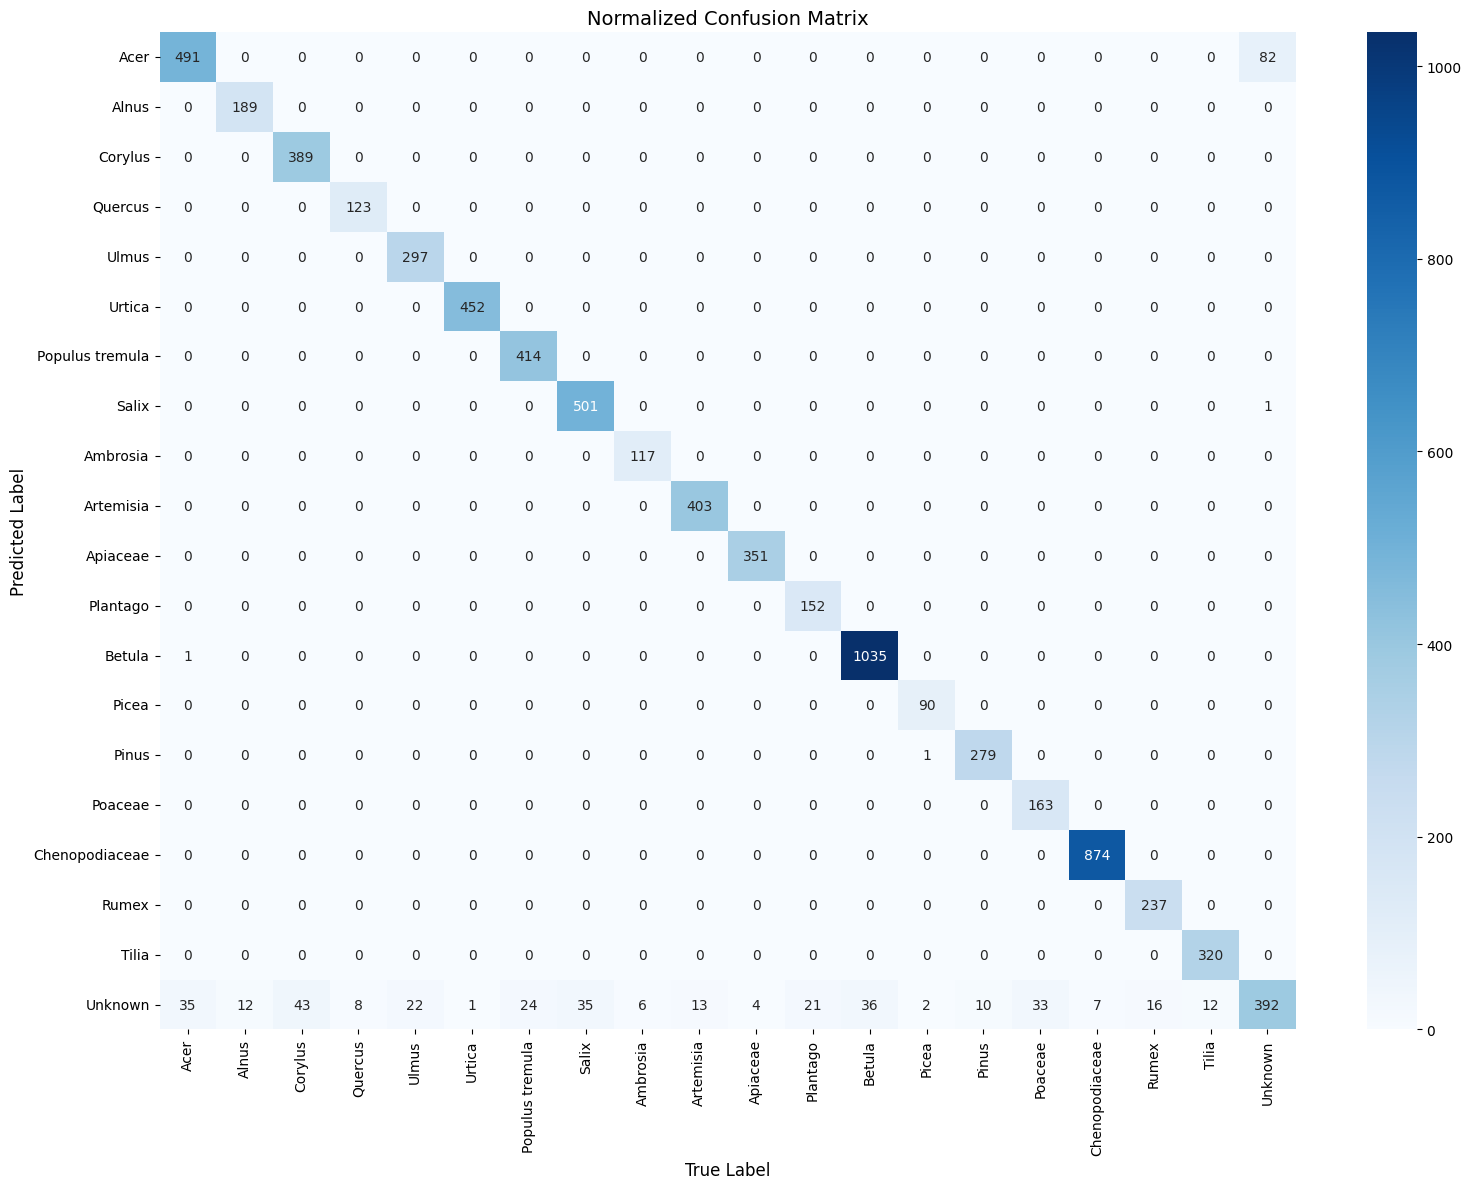

In [18]:
df = plot_confusion_matrix(trainval_ref_y, trainval_ref_pred, os.path.join("out", "cm_lab_trainval.svg"))
df.to_csv(os.path.join("out", "cm_lab_trainval.csv"))

#### Lab reference test subset

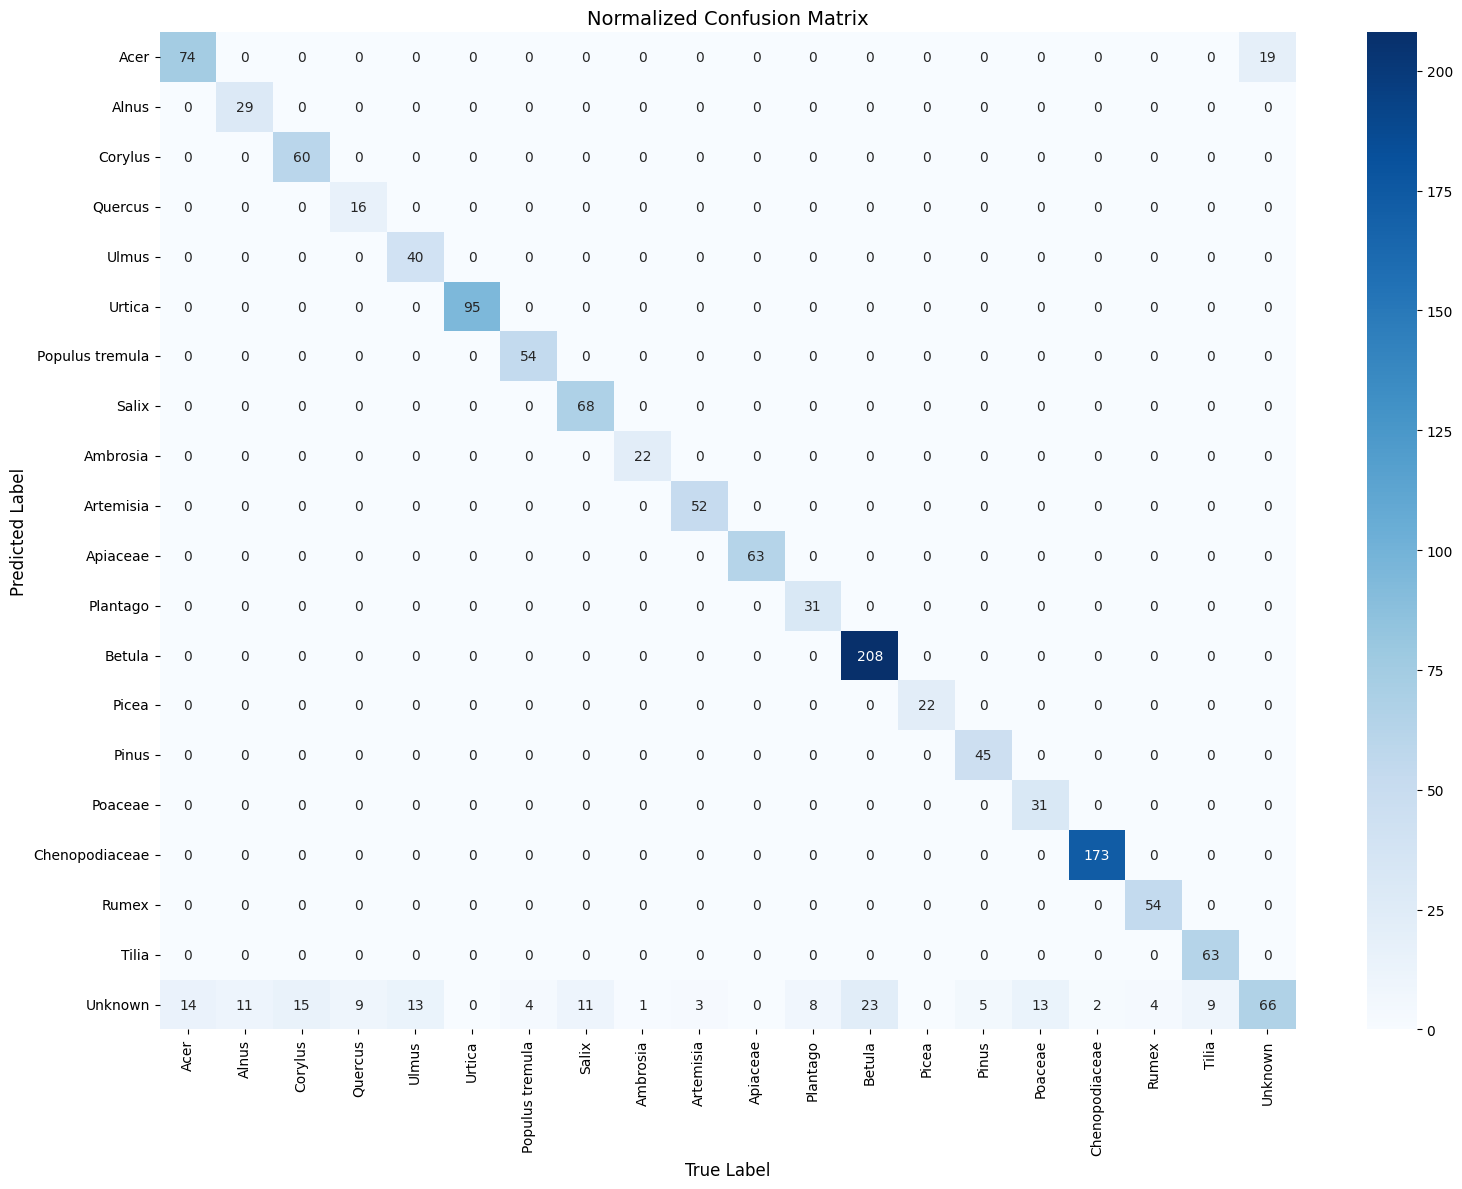

In [19]:
plot_confusion_matrix(test_ref_y, test_ref_pred, os.path.join("out", "cm_lab_tst.svg")).to_csv(os.path.join("out", "cm_lab_tst.csv"))


In [20]:
print(f"Balanced accuracy: {balanced_accuracy_score(test_ref_y, test_ref_pred)}")
print(f"Accuracy: {accuracy_score(test_ref_y, test_ref_pred)}")

Balanced accuracy: 0.8662661491235573
Accuracy: 0.8853146853146853


#### Entire Lab reference dataset

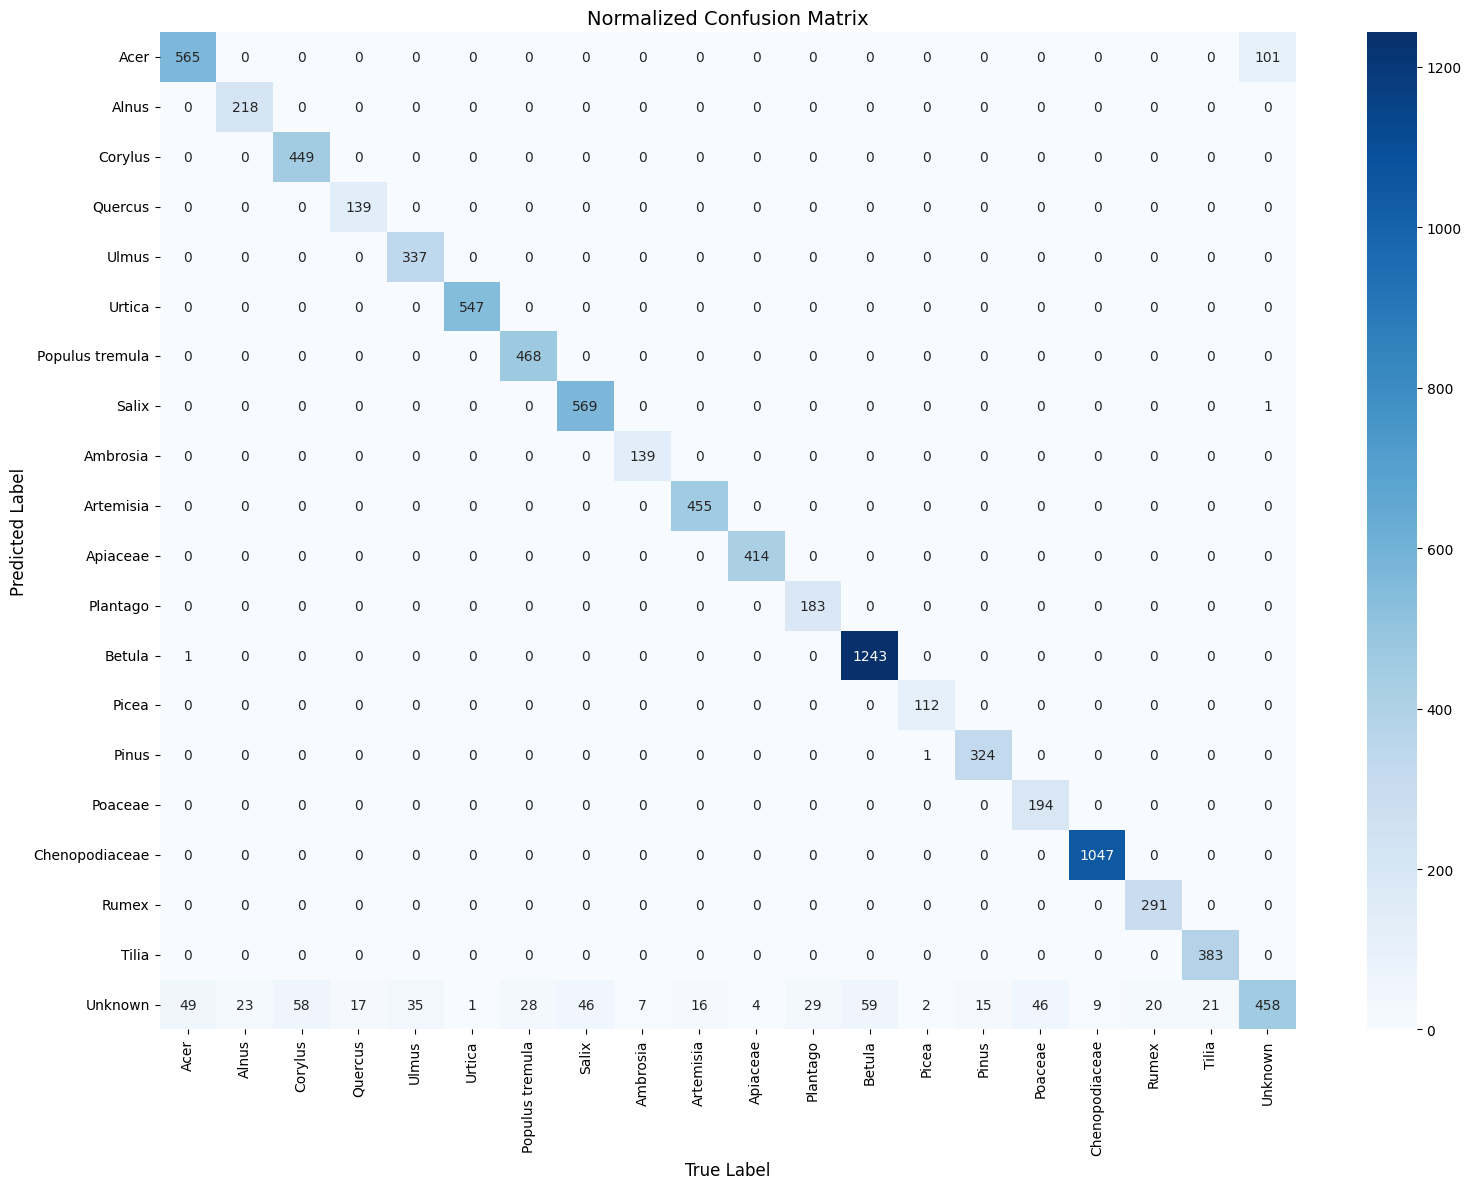

In [21]:
plot_confusion_matrix(
    np.concatenate([trainval_ref_y, test_ref_y]), 
    np.concatenate([trainval_ref_pred, test_ref_pred]), 
    os.path.join("out", "cm_lab_entire.svg")
).to_csv(os.path.join("out", "cm_lab_entire.csv"))

#### Trap reference test dataset

In [22]:
hist_pred  = [classify_with_threshold(item, optimal_thresh)[2] for item in hist_x]

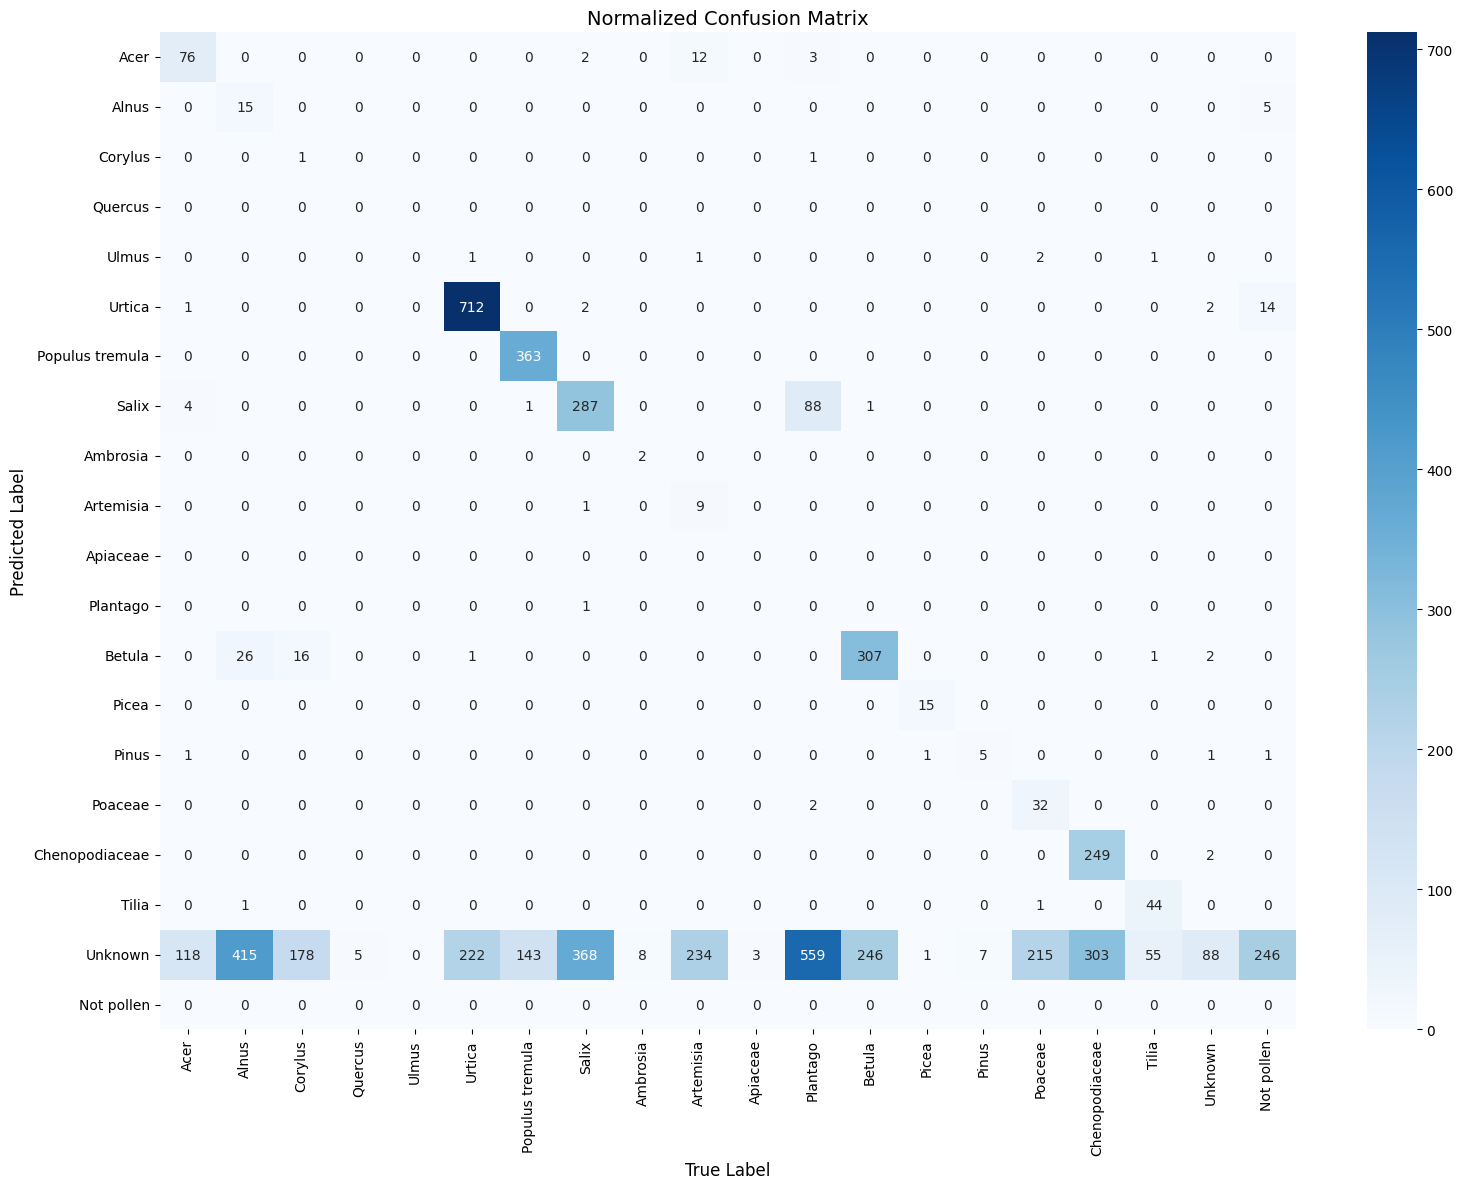

In [23]:
plot_confusion_matrix(hist_y, hist_pred, os.path.join("out", "cm_trap.svg")).to_csv(os.path.join("out", "cm_trap.csv"))

In [24]:
print(f"Balanced accuracy: {balanced_accuracy_score(hist_y, hist_pred)}")
print(f"Accuracy: {accuracy_score(hist_y, hist_pred)}")

Balanced accuracy: 0.3346408140684504
Accuracy: 0.38481675392670156


i:\git\Pollen-Analyzer\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Optimal threshold: 4.974
  Macro-sensitivity: 0.721
  Specificity: 0.532
['Acer', 'Alnus', 'Artemisia', 'Betula', 'Chenopodiaceae', 'Corylus', 'Plantago', 'Poaceae', 'Populus tremula', 'Salix', 'Tilia', 'Urtica']


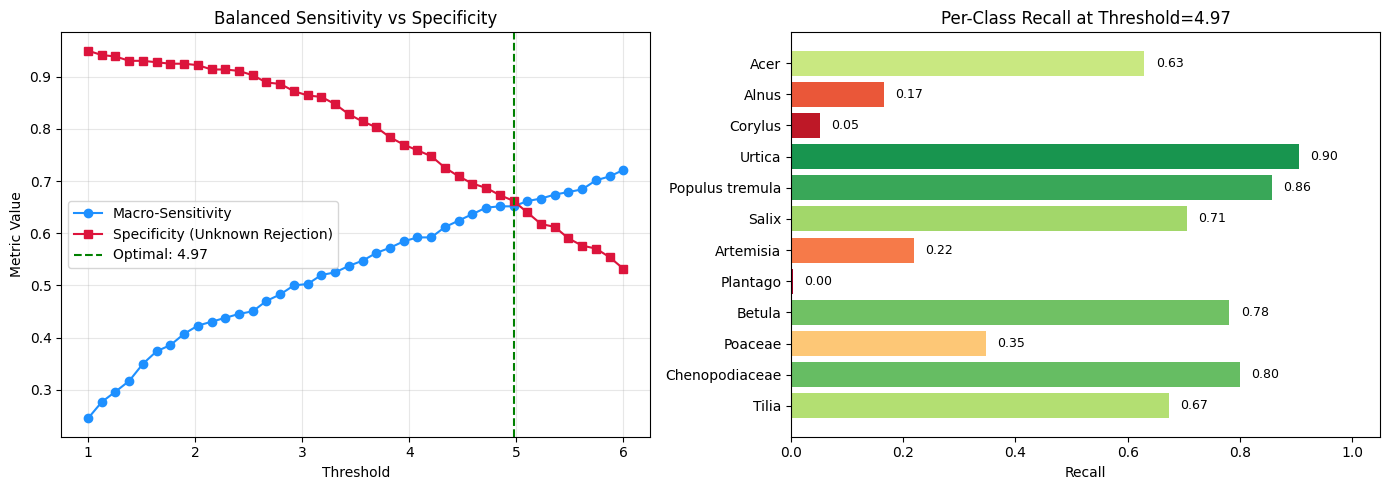

In [25]:
hist_y_masked = hist_y.copy()
hist_y_masked.loc[hist_y == "Not pollen"] = "Unknown"
trap_thresh = find_threshold(np.concatenate([hist_x]), np.concatenate([hist_y_masked]), macro_fcn=np.median, file_name=os.path.join("out", "trap_find_threshold.svg"))

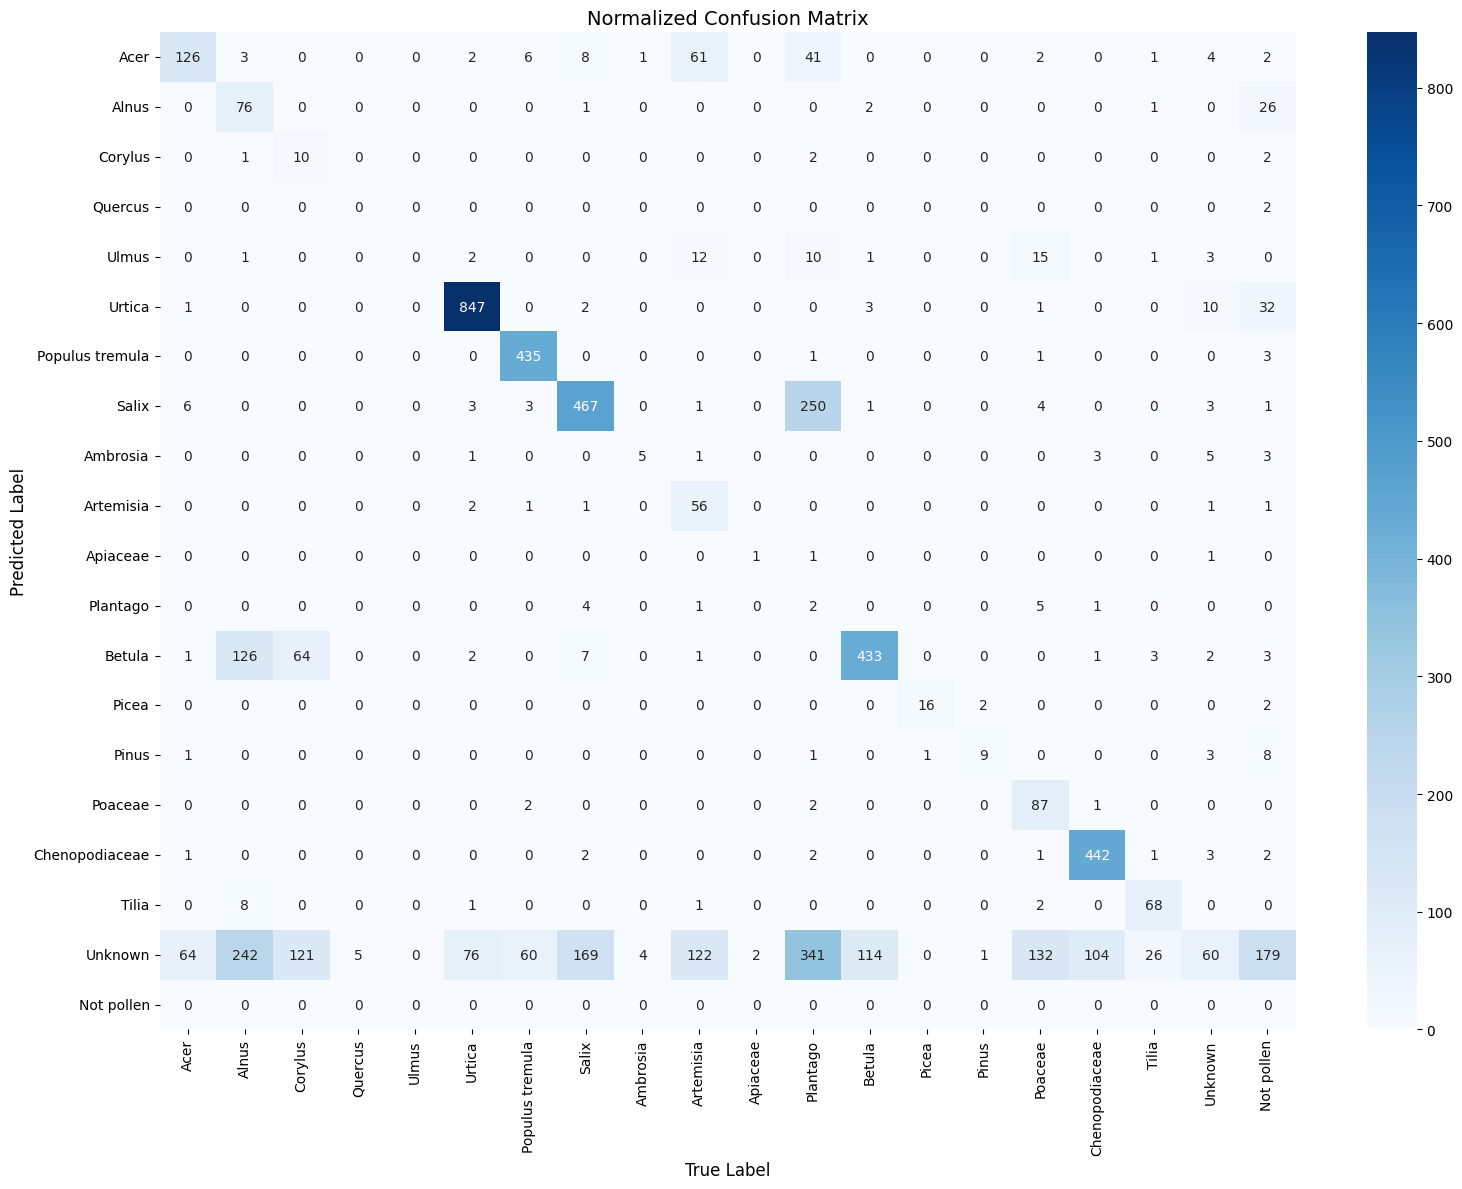

In [26]:
hist_pred_2  = [classify_with_threshold(item, trap_thresh)[2] for item in hist_x]
plot_confusion_matrix(hist_y, hist_pred_2, os.path.join("out", "cm_trap_new_th.svg")).to_csv(os.path.join("out", "cm_trap_new_th.csv"))

In [27]:
print(f"Balanced accuracy: {balanced_accuracy_score(hist_y, hist_pred_2)}")
print(f"Accuracy: {accuracy_score(hist_y, hist_pred_2)}")

Balanced accuracy: 0.48939336640755743
Accuracy: 0.5479930191972077


i:\git\Pollen-Analyzer\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


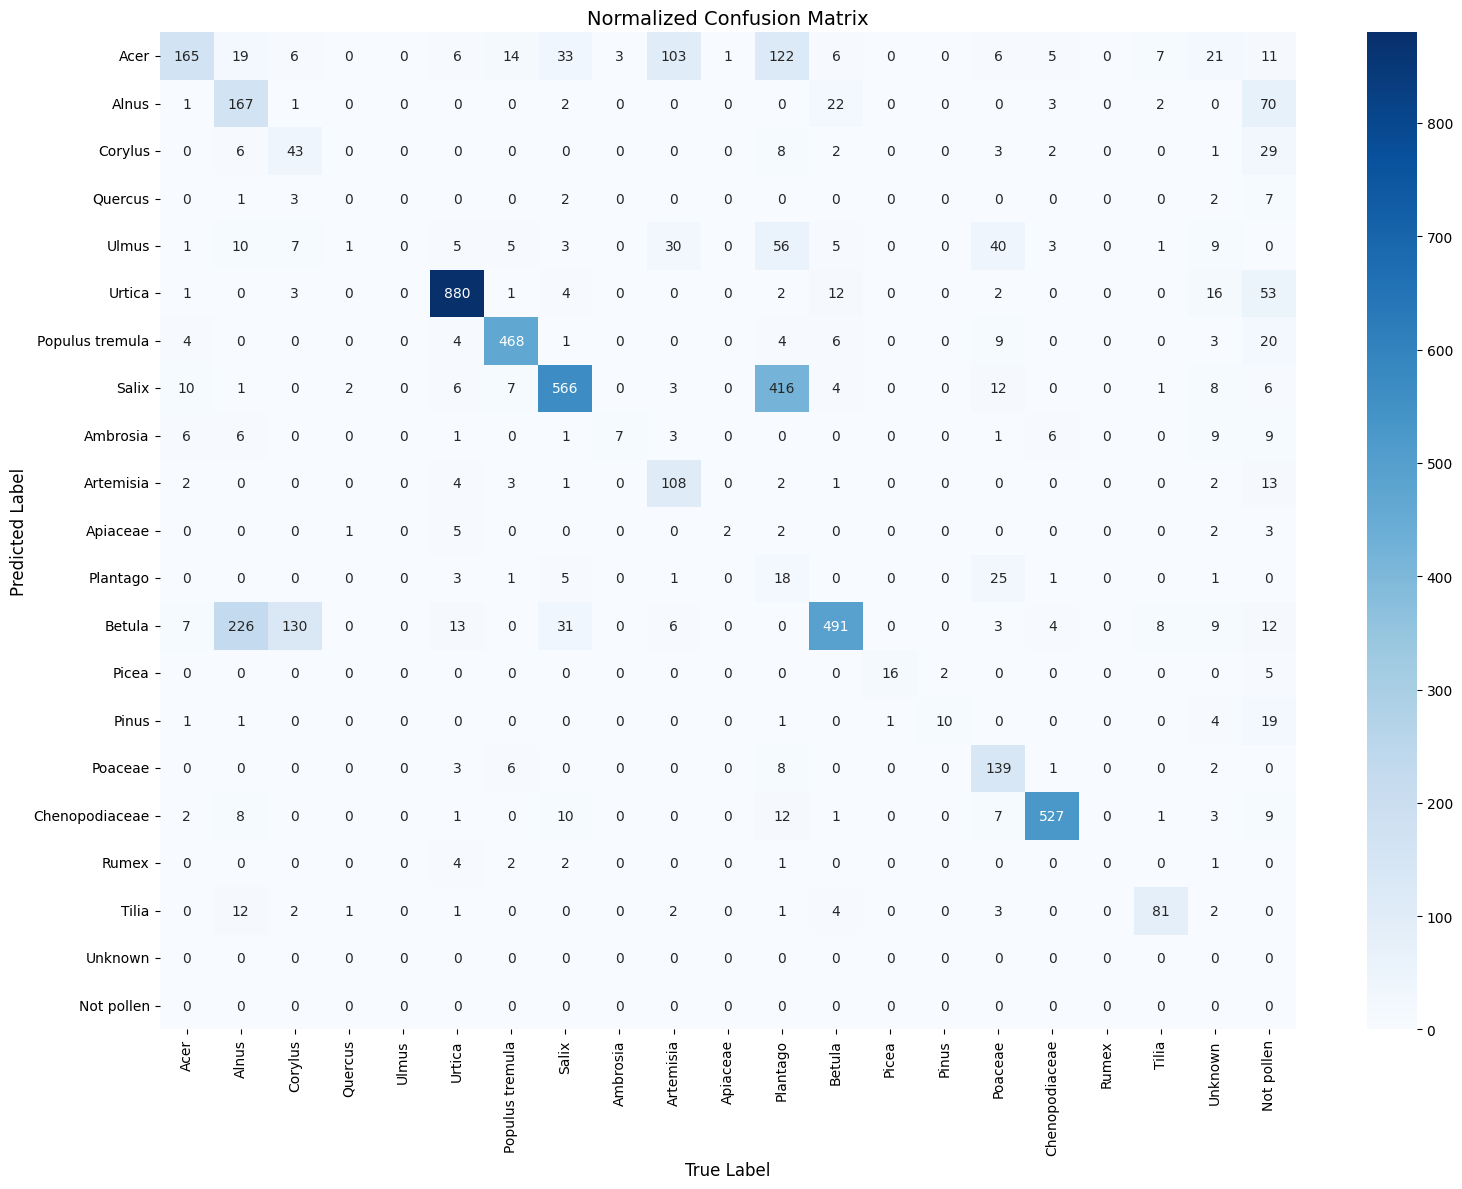

In [28]:
hist_pred_3  = [classify_(item)[2] for item in hist_x]
plot_confusion_matrix(hist_y, hist_pred_3, os.path.join("out", "cm_trap_csc.svg")).to_csv(os.path.join("out", "cm_trap_csc.csv"))

In [29]:
print(f"Balanced accuracy: {balanced_accuracy_score(hist_y, hist_pred_3)}")
print(f"Accuracy: {accuracy_score(hist_y, hist_pred_3)}")

Balanced accuracy: 0.5747396964171031
Accuracy: 0.643630017452007


i:\git\Pollen-Analyzer\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


## Distance maps

In [30]:
def prepare_data(embeddings_lists: np.ndarray, labels_lists: pd.Series):
    all_labels_sorted = []
    class_boundaries = []
 
    class_boundaries.append(len(all_labels_sorted))

    indexes_to_remove = []

    for l in labels_lists.unique():
        l_indexes = labels_lists[labels_lists == l].index
        if len(l_indexes) < 20:
            indexes_to_remove.extend(list(l_indexes))
    
    labels_lists = labels_lists.drop(indexes_to_remove, ).reset_index(drop=True)
    embeddings_lists = np.delete(embeddings_lists, indexes_to_remove, axis=0)
    
    for l in labels_lists.unique():
        l_indexes = labels_lists[labels_lists == l].index
        if len(l_indexes) > 0:
            class_boundaries.append(l_indexes[-1])

    return labels_lists, embeddings_lists, class_boundaries

def add_class_markings(ax, class_boundaries, labels):
    tick_locs = [(class_boundaries[i] + class_boundaries[i+1] - 1) / 2 for i in range(len(class_boundaries)-1)]
    ax.set_xticks(tick_locs)
    ax.set_yticks(tick_locs)
    ax.set_xticklabels([labels[int(loc)] for loc in tick_locs])
    ax.set_yticklabels([labels[int(loc)] for loc in tick_locs])
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    for boundary in class_boundaries[1:-1]:
        ax.axhline(y=boundary-1, color='k', linestyle='-', linewidth=1)
        ax.axvline(x=boundary-1, color='k', linestyle='-', linewidth=1)


def plot_pairwise_distance_map(x, y, file_name=None):
    all_labels_sorted, all_embeddings_sorted, class_boundaries = prepare_data(x, y)
    pairwise_dist = pairwise_distances(all_embeddings_sorted, metric="euclidean")#cosine
    fig, ax = plt.subplots(figsize=(10, 10))
    im = ax.imshow(pairwise_dist, cmap='Blues_r')#, norm=PowerNorm(gamma=0.5, vmin=0, vmax=10)
    plt.colorbar(im, fraction=0.046, pad=0.04)

    add_class_markings(ax, class_boundaries, all_labels_sorted)
    plt.title('Pairwise Distance Matrix')
    plt.tight_layout()
    if file_name:
        plt.savefig(file_name)
    plt.show()


#### Lab reference train-validation subset

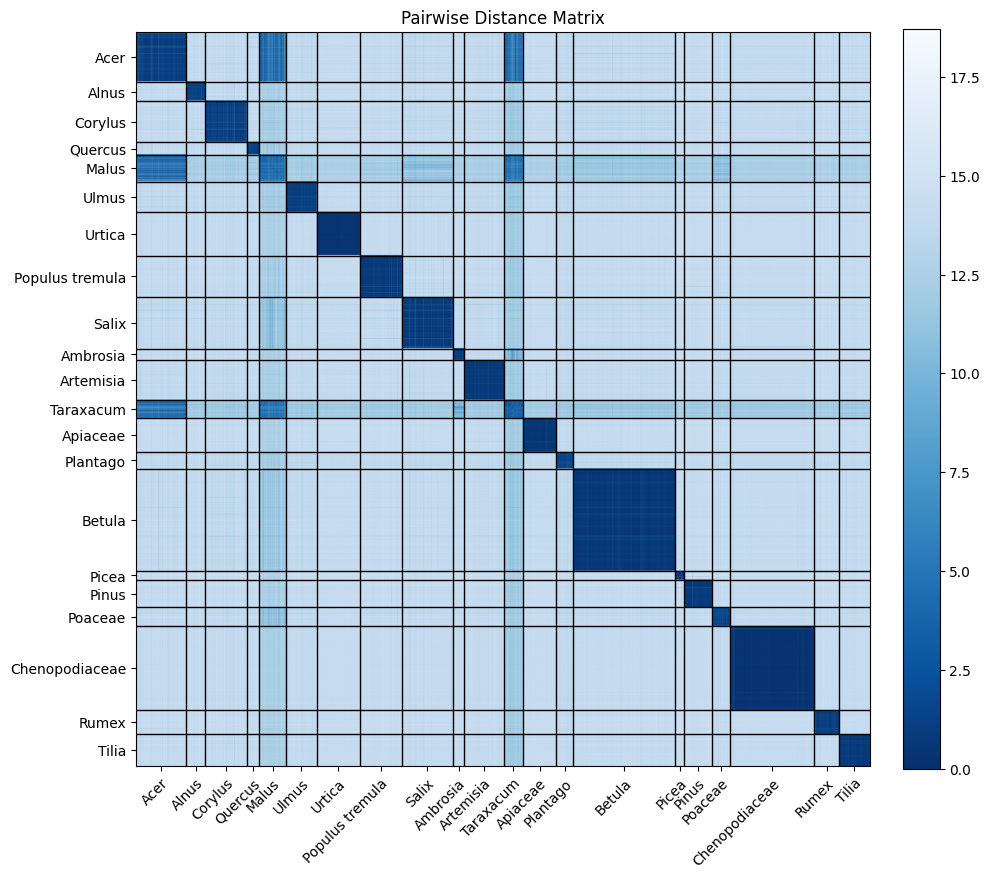

In [31]:
plot_pairwise_distance_map(trainval_ref_unmasked_x, trainval_ref_unmasked_y, os.path.join("out", "emd_dist_map_lab_tv.svg"))


#### Lab reference test subset

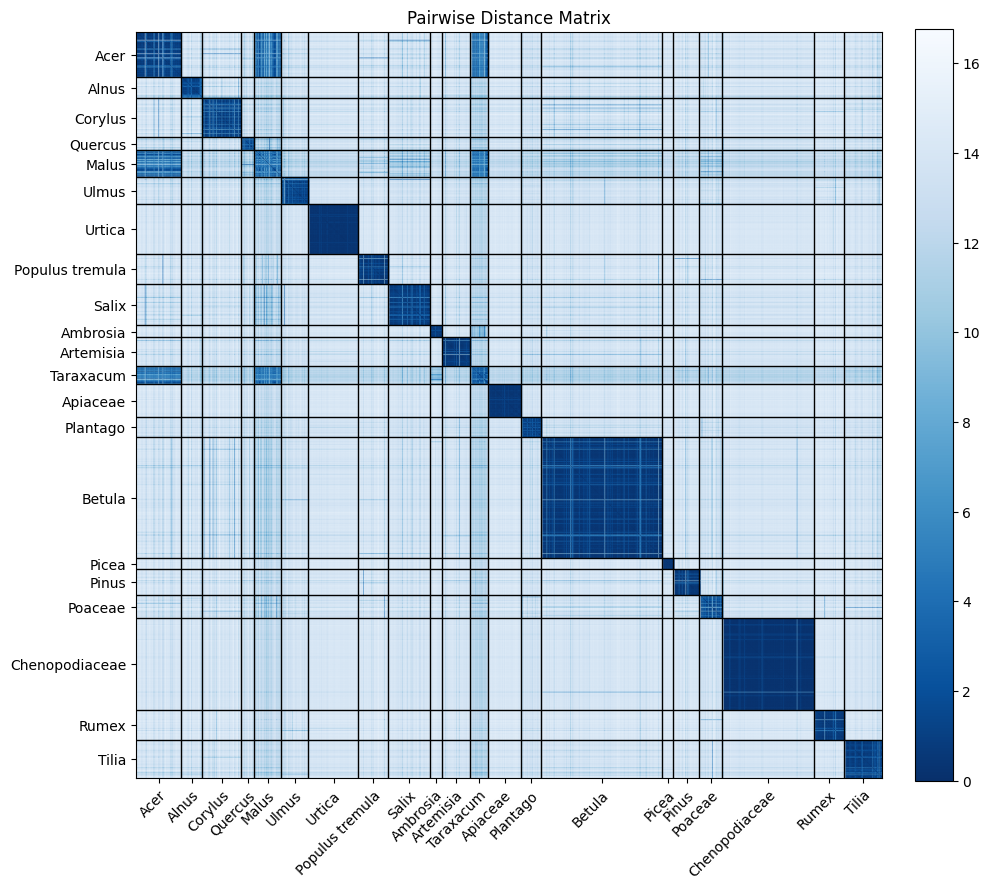

In [32]:
plot_pairwise_distance_map(test_ref_unmasked_x, test_ref_unmasked_y, os.path.join("out", "emd_dist_map_lab_tst.svg"))

### Trap reference dataset

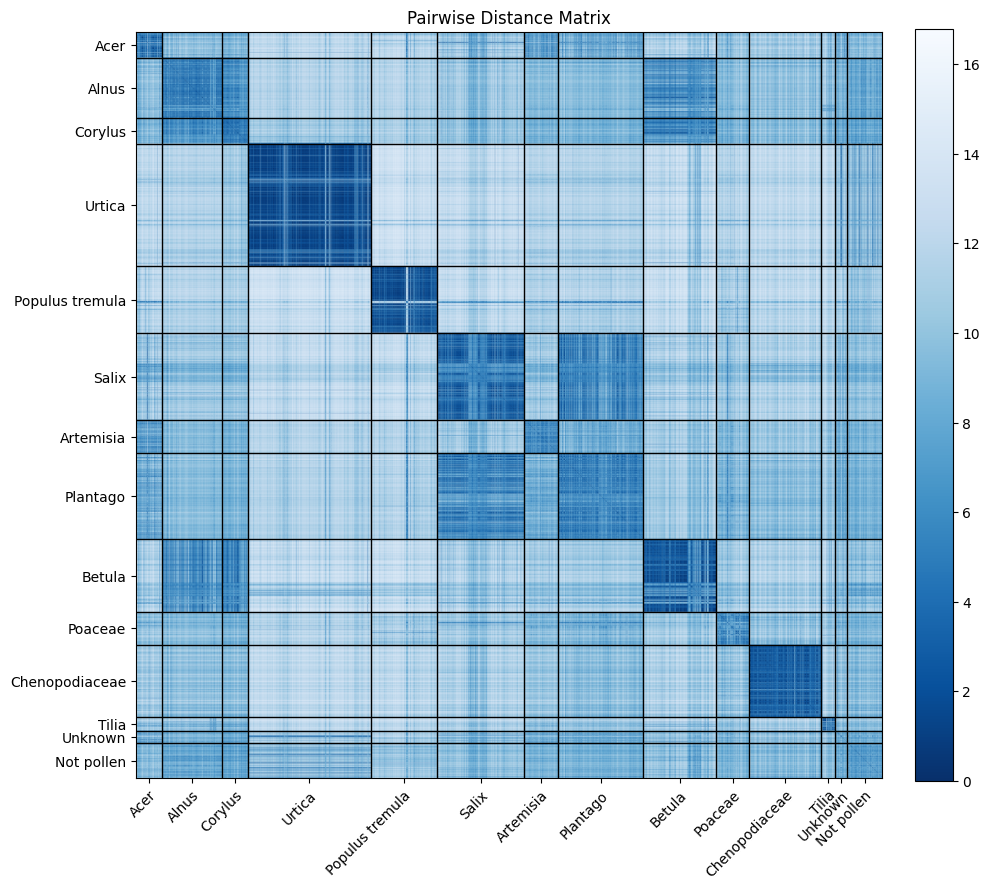

In [33]:
plot_pairwise_distance_map(hist_x, hist_y, os.path.join("out", "emd_dist_map_trap.svg"))